In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math
import copy

In [ ]:
image = cv2.imread('sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image_gray, cmap='gray')

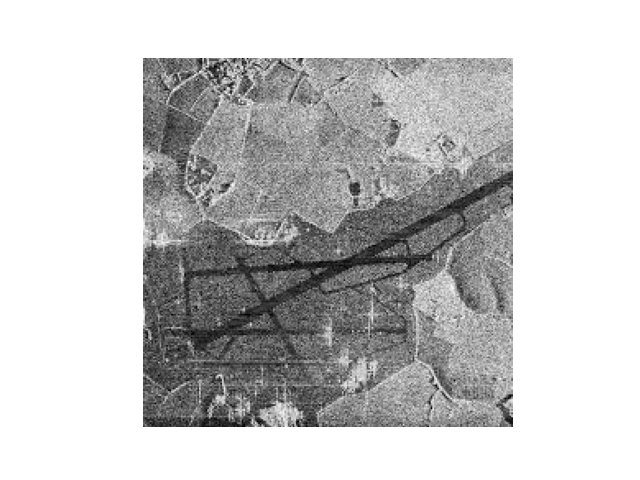

1. Для изображения sar_3.jpg найти наиболее протяженный участок(выделить линии при помощи преобразования Хафа)

In [ ]:
no_noise = cv2.medianBlur(image_gray, 5)
canny = cv2.Canny(no_noise,50,150,apertureSize = 3)
lines = cv2.HoughLines(canny, 1, np.pi / 180, 100)
print(f"Найдено линий: {len(lines)}")
plt.imshow(no_noise, cmap='gray')

Найдено линий: 2

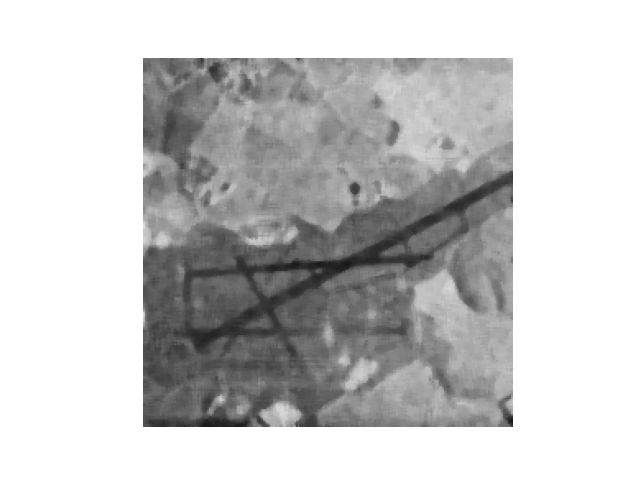

In [ ]:
longest_line = None
max_length = 0

if lines is not None:
    for i in range(len(lines)):
        rho = lines[i][0][0]
        theta = lines[i][0][1]

        a = math.cos(theta)
        b = math.sin(theta)

        x0 = a * rho
        y0 = b * rho

        x1 = int(x0 + 1000 * (-b))
        y1 = int(y0 + 1000 * a)
        x2 = int(x0 - 1000 * (-b))
        y2 = int(y0 - 1000 * a)

        length = math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)

        if length > max_length:
            max_length = length
            longest_line = (x1, y1, x2, y2)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

x1, y1, x2, y2 = longest_line

cv2.line(image_rgb,(x1, y1),(x2, y2),(255, 0, 0),3)

print(f"Длина линии: {max_length:.2f}")

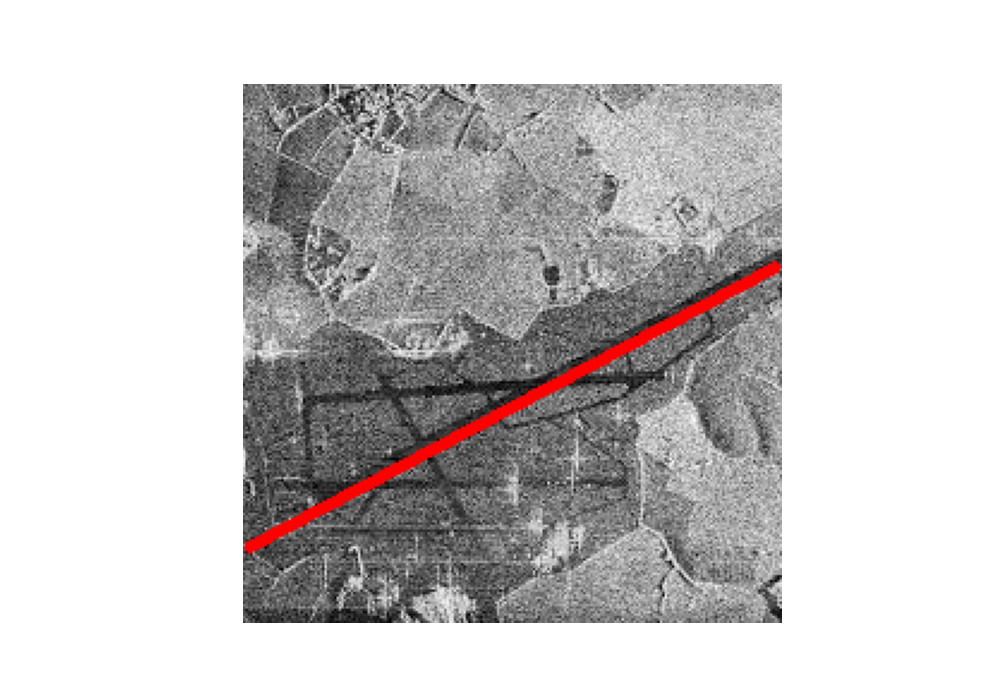

Длина линии: 254.12

2. Для изображения sar_3.jpg провести исследование алгоритмов бинаризации, выделить участок дорожной полосы.

In [ ]:
# Точечная бинаризация
bin_img = copy.deepcopy(image_gray)
T = 75
bin_img[image_gray < T] = 0
bin_img[image_gray >=T] = 255
plt.imshow(bin_img, cmap='gray')

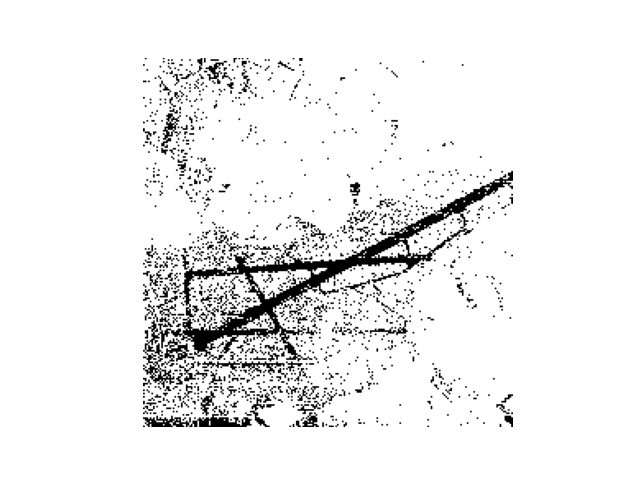

In [ ]:
#Отсу
_, th2 = cv2.threshold(image_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
plt.imshow(th2, cmap="gray")

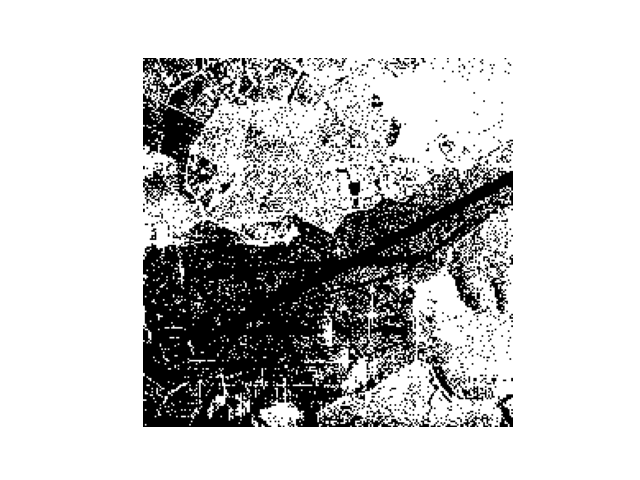

In [ ]:
# Адаптивная бинаризация
th3 = cv2.adaptiveThreshold(image_gray,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
            cv2.THRESH_BINARY,71,21)
plt.imshow(th3, cmap="gray")

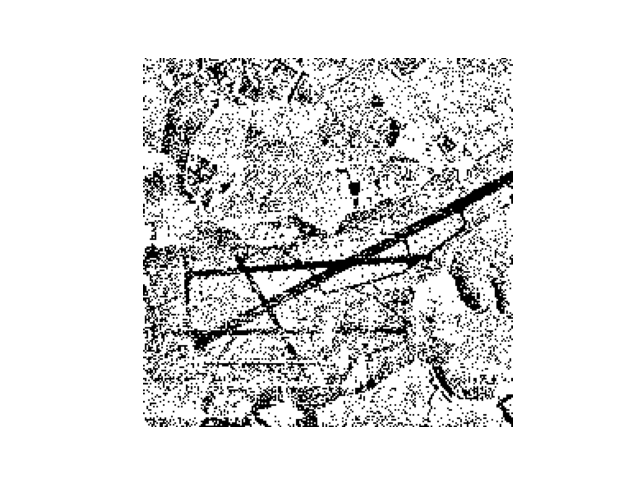